# Result charts for the deck
Charts built from the pipeline's outputs after a full run: the business-value **risk ladder**, and monitoring
charts coloured by **which model was in production**. Reads `datamart/gold/`; saves `notebooks/figures/deck_*.png`.
Exploratory charts from the raw data are in `eda.ipynb`.

In [1]:
import glob
import os
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datamart").exists())
FIGURES = ROOT / "notebooks" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# deck colours
NAVY, INK, BODY, MUTED, GRID = "#14213D", "#1F2933", "#4A5568", "#6B7280", "#E3E8EF"
BLUE, RUST, GREEN = "#2D72D2", "#D9773F", "#238551"
plt.rcParams.update({
    "font.family": "Calibri", "font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": BODY,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,   # gridlines behind bars and lines
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})


def save(fig, name):
    fig.savefig(FIGURES / f"deck_{name}.png", dpi=220, bbox_inches="tight")


MON = ROOT / "datamart" / "gold" / "model_monitoring"
# one colour per champion: blues while clickstream existed, green after it stopped
CHAMP = {"2024-01": "#8AB4F8", "2024-02": "#5B8FDB", "2024-03": "#2D72D2", "2024-05": "#1E4FA0", "2024-07": GREEN}


def champ_key(version):
    return version[len("credit_model_"):][:7].replace("_", "-")


def label(version):
    date = pd.to_datetime(champ_key(version) + "-01")
    return f"{'LR' if '_logreg' in version else 'XGB'} {date:%b %y}"

## 1. Risk ladder: where the defaults sit
Every application scored from January 2024 to January 2025, with its real outcome 6 months later, ranked by
model score and cut into tenths. Inside each bar: that tenth's share of **all** defaults and of **all** good borrowers.

In [2]:
pred = pd.concat(pd.read_parquet(p) for p in glob.glob(str(ROOT / "datamart/gold/model_predictions/predictions_*.parquet")))
lab = pd.concat(pd.read_parquet(p) for p in glob.glob(str(ROOT / "datamart/gold/label_store/*.parquet")))
lab["loan_start_date"] = pd.to_datetime(lab["loan_start_date"]).dt.strftime("%Y-%m-%d")
pred["snapshot_date"] = pd.to_datetime(pred["snapshot_date"]).dt.strftime("%Y-%m-%d")
live = pred.merge(lab[["Customer_ID", "loan_start_date", "label"]],
                  left_on=["Customer_ID", "snapshot_date"], right_on=["Customer_ID", "loan_start_date"])
live = live.sort_values("model_predictions", ascending=False).reset_index(drop=True)
live["tenth"] = np.arange(len(live)) * 10 // len(live)
ladder = live.groupby("tenth")["label"].agg(defaults="sum", applicants="size")
ladder["good"] = ladder["applicants"] - ladder["defaults"]
ladder["share_of_defaults"] = ladder["defaults"] / ladder["defaults"].sum()
ladder["share_of_good"] = ladder["good"] / ladder["good"].sum()
print(f"{len(live):,} applications, default rate {live['label'].mean():.1%}")
ladder.round(3)

6,542 applications, default rate 29.3%


,defaults,applicants,good,share_of_defaults,share_of_good
tenth,,,,,
0,532,655,123,0.278,0.027
1,443,654,211,0.231,0.046
2,325,654,329,0.170,0.071
3,215,654,439,0.112,0.095
4,140,654,514,0.073,0.111
5,95,655,560,0.050,0.121
6,81,654,573,0.042,0.124
7,49,654,605,0.026,0.131
8,31,654,623,0.016,0.135


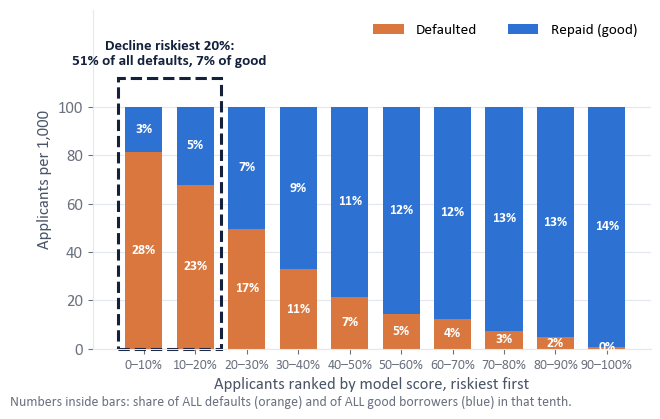

In [3]:
scale = 1000 / len(live)
x = np.arange(10)
d, g = ladder["defaults"] * scale, ladder["good"] * scale
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.bar(x, d, color=RUST, width=0.72, label="Defaulted")
ax.bar(x, g, bottom=d, color=BLUE, width=0.72, label="Repaid (good)")
for i in x:
    ax.text(i, d.iloc[i] / 2, f"{ladder['share_of_defaults'].iloc[i]:.0%}", ha="center", va="center",
            color="white", fontsize=10, fontweight="bold")
    ax.text(i, d.iloc[i] + g.iloc[i] / 2, f"{ladder['share_of_good'].iloc[i]:.0%}", ha="center", va="center",
            color="white", fontsize=10, fontweight="bold")
ax.add_patch(Rectangle((-0.5, 0), 2, 112, fill=False, ec=NAVY, lw=2.2, ls="--", clip_on=False))
top_d, top_g = ladder["share_of_defaults"].iloc[:2].sum(), ladder["share_of_good"].iloc[:2].sum()
ax.text(0.5, 116, f"Decline riskiest 20%:\n{top_d:.0%} of all defaults, {top_g:.0%} of good", ha="center",
        va="bottom", color=NAVY, fontsize=11, fontweight="bold")
ax.set(xticks=x, xticklabels=[f"{10 * i}–{10 * (i + 1)}%" for i in x], ylim=(0, 140), yticks=range(0, 101, 20),
       xlabel="Applicants ranked by model score, riskiest first", ylabel="Applicants per 1,000")
ax.tick_params(axis="x", labelsize=10)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncol=2, fontsize=11)
fig.text(0.01, -0.02, "Numbers inside bars: share of ALL defaults (orange) and of ALL good borrowers (blue) in that tenth.",
         fontsize=10, color=MUTED)
save(fig, "risk_ladder")
plt.show()

> **Takeaway:** the riskiest two tenths hold 51% of all defaults but only 7% of good borrowers, while the safest
tenths are almost all good. That is why declining the riskiest 20% cuts the approved default rate from 29% to 18%.

## 2. Monitoring, coloured by the model in production

In [4]:
mon = pd.concat(pd.read_parquet(p) for p in glob.glob(str(MON / "monitoring_*.parquet")))
mon["cohort_date"] = pd.to_datetime(mon["cohort_date"])
perf = mon[mon.metric_type == "performance"].sort_values("cohort_date")
stab = mon[mon.metric_type == "stability"].sort_values("cohort_date")
shadow = mon[mon.metric_type == "shadow"].sort_values("cohort_date")


def by_champion(ax, rows, column):
    """One line per champion, each in its own colour, joined lightly across hand-overs."""
    ax.plot(rows["cohort_date"], rows[column], color="#C9D1DB", lw=1, zorder=1)
    for version, part in rows.groupby("model_version", sort=False):
        ax.plot(part["cohort_date"], part[column], color=CHAMP[champ_key(version)], marker="o", lw=2.6, ms=6,
                label=label(version), zorder=3)


def months(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

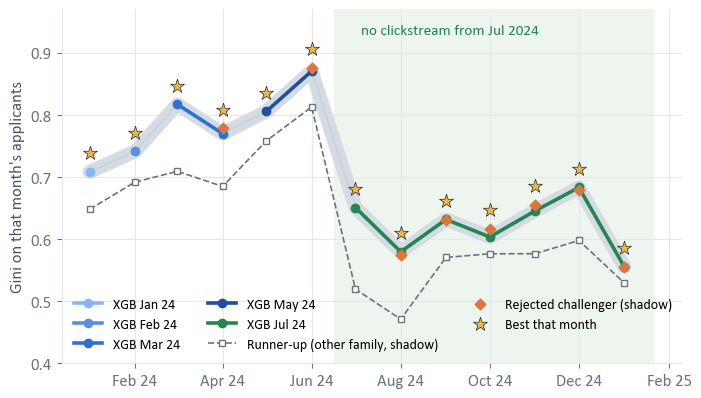

In [5]:
fig, ax = plt.subplots(figsize=(8.0, 4.6))
ax.plot(perf["cohort_date"], perf["gini"], color="#D5DBE3", lw=10, solid_capstyle="round", zorder=1)
by_champion(ax, perf, "gini")
runner_up = shadow[shadow["shadow_model"].str.endswith("_runner_up")]
challenger = shadow[~shadow["shadow_model"].str.endswith("_runner_up")]
ax.plot(runner_up["cohort_date"], runner_up["gini"], color=MUTED, ls="--", lw=1.2, marker="s", ms=5, mfc="white",
        label="Runner-up (other family, shadow)")
ax.scatter(challenger["cohort_date"], challenger["gini"], color=RUST, marker="D", s=30,
           label="Rejected challenger (shadow)", zorder=4)
best = pd.concat([perf[["cohort_date", "gini"]], shadow[["cohort_date", "gini"]]]).groupby("cohort_date")["gini"].max()
ax.scatter(best.index, best.values + 0.03, marker="*", s=110, color="#F2B544", edgecolor=INK, lw=0.5, zorder=6,
           label="Best that month")
ax.axvspan(pd.Timestamp("2024-06-16"), perf["cohort_date"].max() + pd.Timedelta(days=20), color="#EEF5EF", zorder=0)
ax.text(pd.Timestamp("2024-07-05"), 0.93, "no clickstream from Jul 2024", color=GREEN, fontsize=11)
ax.set(ylabel="Gini on that month's applicants", ylim=(0.4, 0.97))
months(ax)
ax.legend(loc="lower left", ncol=3, fontsize=10)
save(fig, "model_lines")
plt.show()

> **Takeaway:** five champions in 13 months; the champion had the best Gini in 9 of them. Live Gini rose with
clickstream history to 0.87 in June 2024, then settled around 0.56 to 0.68 once clickstream stopped.

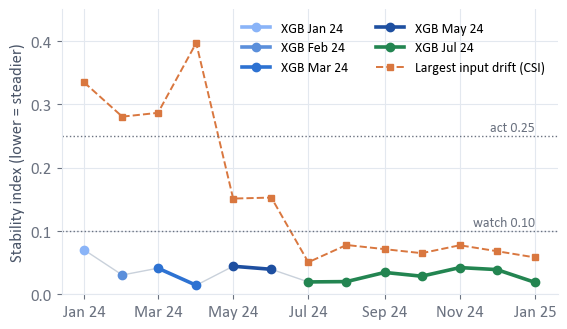

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 3.7))
by_champion(ax, stab, "psi")
ax.plot(stab["cohort_date"], stab["max_csi"], color=RUST, ls="--", lw=1.4, marker="s", ms=4, label="Largest input drift (CSI)")
for value, name in [(0.10, "watch 0.10"), (0.25, "act 0.25")]:
    ax.axhline(value, color=MUTED, lw=1, ls=":")
    ax.text(stab["cohort_date"].max(), value + 0.008, name, ha="right", color=MUTED, fontsize=10)
ax.set(ylabel="Stability index (lower = steadier)", ylim=(0, 0.45))
months(ax)
ax.legend(loc="upper right", ncol=2, fontsize=10)
save(fig, "psi_by_model")
plt.show()

> **Takeaway:** score PSI stayed at or below 0.07 for every model. The clickstream inputs drifted (CSI up to 0.40)
until July 2024; after that no input moved above 0.08.

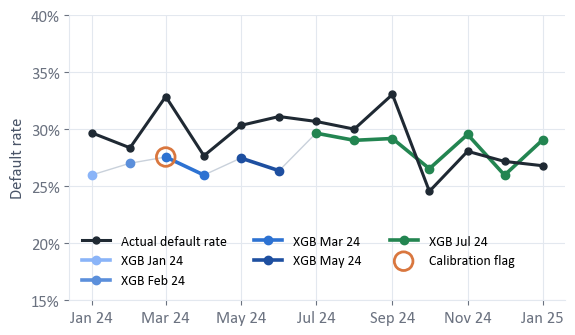

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 3.7))
ax.plot(perf["cohort_date"], perf["bad_rate"], color=INK, lw=2.2, marker="o", ms=5, label="Actual default rate", zorder=4)
by_champion(ax, perf, "mean_prediction")
flag = perf[perf["calibration_flag"].fillna(False).astype(bool)]
ax.scatter(flag["cohort_date"], flag["mean_prediction"], s=180, facecolors="none", edgecolors=RUST, lw=2, zorder=5,
           label="Calibration flag")
ax.set(ylabel="Default rate", ylim=(0.15, 0.40))
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
months(ax)
ax.legend(loc="lower left", ncol=3, fontsize=10)
save(fig, "calibration_by_model")
plt.show()

> **Takeaway:** predictions ran 1 to 5 points below the actual default rate until mid-2024, then close to it.
The one flag (March 2024, 5.3 points under) rests on a single month of about 500 loans.